In [1]:
#1 Imports
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, roc_curve
)

In [2]:
from google.colab import files

uploaded = files.upload()

Saving X_test_medianonly.csv to X_test_medianonly.csv
Saving X_train_medianonly.csv to X_train_medianonly.csv
Saving y_test_medianonly.csv to y_test_medianonly.csv
Saving y_train_medianonly.csv to y_train_medianonly.csv


In [3]:
#2 Loading the leakage-free, pre-split, pre-imputed data
X_train = pd.read_csv("X_train_medianonly.csv")
X_test = pd.read_csv("X_test_medianonly.csv")
y_train = pd.read_csv("y_train_medianonly.csv").squeeze()
y_test = pd.read_csv("y_test_medianonly.csv").squeeze()


print("Train shape:", X_train.shape)
print("Test shape :", X_test.shape)

Train shape: (614, 8)
Test shape : (154, 8)


In [4]:
#3 Building the SMOTE + XGBoost pipeline
xgb_pipeline = ImbPipeline([
    ("smote", SMOTE(random_state=42)),
    ("clf", XGBClassifier(
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    ))
])

In [5]:
#4 Defining the hyperparameter search space
param_dist = {
    "clf__n_estimators": [100, 200, 300, 400, 500],
    "clf__max_depth": [3, 4, 5, 6, 8],
    "clf__learning_rate": [0.01, 0.05, 0.1, 0.2],
    "clf__subsample": [0.6, 0.8, 1.0],
    "clf__colsample_bytree": [0.6, 0.8, 1.0],
    "clf__min_child_weight": [1, 3, 5],
    "clf__gamma": [0, 0.1, 0.3],
    "clf__reg_alpha": [0, 0.1, 1],
    "clf__reg_lambda": [1, 1.5, 2]
}

In [6]:
#5 Cross-validation strategy
cv_strategy = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

In [7]:
#6 Running RandomizedSearchCV
xgb_random_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_dist,
    n_iter=50,
    scoring="roc_auc",
    cv=cv_strategy,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

xgb_random_search.fit(X_train, y_train)

print("Best Parameters:", xgb_random_search.best_params_)
print("Best CV ROC-AUC:", xgb_random_search.best_score_)

Fitting 10 folds for each of 50 candidates, totalling 500 fits
Best Parameters: {'clf__subsample': 0.6, 'clf__reg_lambda': 2, 'clf__reg_alpha': 1, 'clf__n_estimators': 200, 'clf__min_child_weight': 3, 'clf__max_depth': 3, 'clf__learning_rate': 0.01, 'clf__gamma': 0.1, 'clf__colsample_bytree': 1.0}
Best CV ROC-AUC: 0.8330140692640693


In [8]:
#7 Evaluating the tuned XGBoost model on the test set
best_xgb_model = xgb_random_search.best_estimator_

y_pred_xgb = best_xgb_model.predict(X_test)
y_prob_xgb = best_xgb_model.predict_proba(X_test)[:, 1]

accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
precision_xgb = precision_score(y_test, y_pred_xgb)
recall_xgb = recall_score(y_test, y_pred_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb)
roc_auc_xgb = roc_auc_score(y_test, y_prob_xgb)

print("="*50)
print("TUNED XGBOOST RESULTS")
print("="*50)
print(f"Accuracy : {accuracy_xgb:.4f}")
print(f"Precision: {precision_xgb:.4f}")
print(f"Recall   : {recall_xgb:.4f}")
print(f"F1 Score : {f1_xgb:.4f}")
print(f"ROC AUC  : {roc_auc_xgb:.4f}")

print("\nClassification Report")
print(classification_report(y_test, y_pred_xgb))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred_xgb))

TUNED XGBOOST RESULTS
Accuracy : 0.7468
Precision: 0.6087
Recall   : 0.7778
F1 Score : 0.6829
ROC AUC  : 0.8246

Classification Report
              precision    recall  f1-score   support

           0       0.86      0.73      0.79       100
           1       0.61      0.78      0.68        54

    accuracy                           0.75       154
   macro avg       0.73      0.75      0.74       154
weighted avg       0.77      0.75      0.75       154


Confusion Matrix
[[73 27]
 [12 42]]


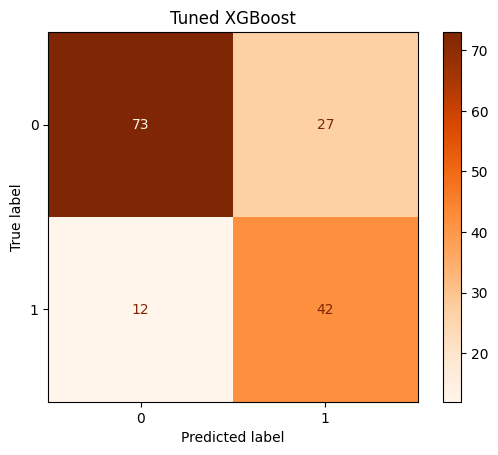

In [9]:
#8 Plotting Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_xgb,
    cmap="Oranges"
)
plt.title("Tuned XGBoost")
plt.show()

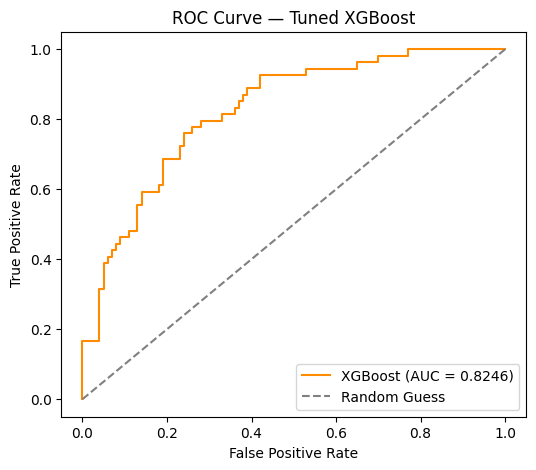

In [10]:
#9 Plotting ROC Curve
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_prob_xgb)

plt.figure(figsize=(6, 5))
plt.plot(fpr_xgb, tpr_xgb, color="darkorange", label=f"XGBoost (AUC = {roc_auc_xgb:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Tuned XGBoost")
plt.legend(loc="lower right")
plt.show()

In [11]:
#10 Feature Importance
feat_importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_xgb_model.named_steps["clf"].feature_importances_
}).sort_values(by="Importance", ascending=False)

print(feat_importance_df)

                    Feature  Importance
1                   Glucose    0.317695
5                       BMI    0.180862
7                       Age    0.125425
4                   Insulin    0.101970
6  DiabetesPedigreeFunction    0.094253
2             BloodPressure    0.064802
3             SkinThickness    0.063897
0               Pregnancies    0.051096


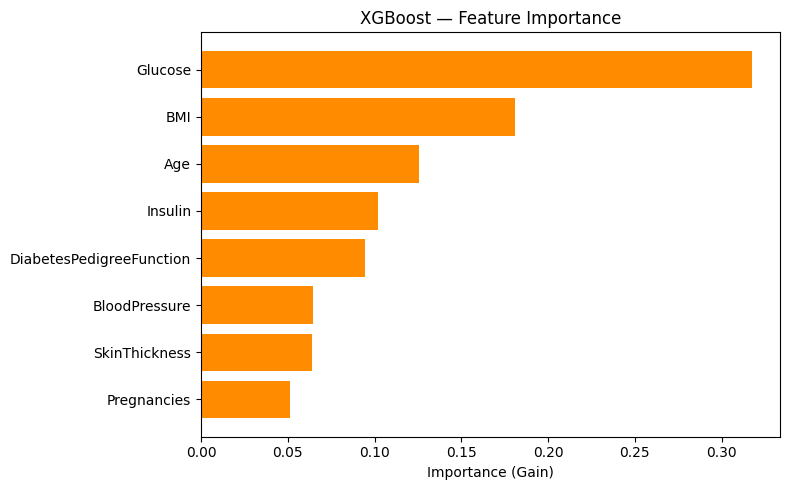

In [12]:
#11 Plotting Feature Importance
plt.figure(figsize=(8, 5))
plt.barh(feat_importance_df["Feature"], feat_importance_df["Importance"], color="darkorange")
plt.gca().invert_yaxis()
plt.xlabel("Importance (Gain)")
plt.title("XGBoost — Feature Importance")
plt.tight_layout()
plt.show()

In [13]:
#12 Three-Model Comparison Table
comparison_df = pd.DataFrame({
   "Logistic Regression": [0.7078, 0.5714, 0.6667, 0.6154, 0.8050],
    "Random Forest": [0.7468, 0.6056,  0.7963,  0.6880, 0.8246],
    "XGBoost": [accuracy_xgb, precision_xgb, recall_xgb, f1_xgb, roc_auc_xgb]
}, index=["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"])

print(comparison_df.round(4))

           Logistic Regression  Random Forest  XGBoost
Accuracy                0.7078         0.7468   0.7468
Precision               0.5714         0.6056   0.6087
Recall                  0.6667         0.7963   0.7778
F1-Score                0.6154         0.6880   0.6829
ROC-AUC                 0.8050         0.8246   0.8246
